In [ ]:
'''
Script that takes the paths for the original spreadsheet, the folder with the train set and the folder with the validation set
and produces a new spreadsheet with additional columns with properties of the images comprising the dataset.

For a preliminary analysis of a dataset intended for object detection it's important to focus on properties that provide insights into the dataset's characteristics and variability, without delving too deeply into complex feature extractions.
We look into the following properties:
- Image Dimensions: Width and height of each image. This helps to understand the size distribution of the images and whether any resizing or normalization is needed.
- Aspect Ratio: The ratio of width to height. This can be important for understanding how much variation there is in the shapes of the images.
- Color Distribution: Basic color analysis based on the average intensity per channel (Red, Green, Blue).
- Contrast and Brightness: Basic statistics on the brightness and contrast of the images can be useful to assess the need for pre-processing steps like contrast normalization.
- Presence of Blurriness assessed using the variance of the Laplacian.
'''

In [ ]:
import os
import cv2
import pandas as pd
import numpy as np
import tkinter as tk
from tkinter import filedialog
from datetime import datetime

# Function to calculate image properties
def get_image_properties(image_path):
    image = cv2.imread(image_path)
    height, width, channels = image.shape

    # Calculating aspect ratio
    aspect_ratio = width / height if height != 0 else 0

    # Calculating average intensity per channel (Red, Green, Blue)
    avg_intensity_per_channel = np.mean(image, axis=(0, 1))
    avg_red_intensity = avg_intensity_per_channel[0]
    avg_green_intensity = avg_intensity_per_channel[1]
    avg_blue_intensity = avg_intensity_per_channel[2]

    # Calculating brightness and contrast
    brightness = np.mean(avg_intensity_per_channel)
    contrast = np.std(image)

    # Blurriness
    laplacian_var = cv2.Laplacian(image, cv2.CV_64F).var()

    return width, height, aspect_ratio, avg_red_intensity, avg_green_intensity, avg_blue_intensity, brightness, contrast, laplacian_var

# Main function to update the spreadsheet with image properties
def update_spreadsheet_with_image_properties():
    
    # Load the spreadsheet
    root = tk.Tk()
    root.withdraw()  # Hide the main window

    # Open file dialog to select the spreadsheet file
    spreadsheet_path = filedialog.askopenfilename(
        title="Select the Spreadsheet File",
        filetypes=[("Excel files", "*.xlsx")]
    )
    
    # Open directory dialogs to select train and validation folders
    train_folder_path = filedialog.askdirectory(title="Select Train Set Folder")
    validation_folder_path = filedialog.askdirectory(title="Select Validation Set Folder")
    
    if not (spreadsheet_path and train_folder_path and validation_folder_path):
        return "File paths must be provided."

    # Read the spreadsheet
    spreadsheet = pd.ExcelFile(spreadsheet_path)

    # Process Train Set
    train_df = pd.read_excel(spreadsheet, 'train_set')
    train_df[['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 'Avg Green Intensity', 
              'Avg Blue Intensity', 'Brightness', 'Contrast', 'Blurriness']] = None

    for idx, row in train_df.iterrows():
        patient_folder = os.path.join(train_folder_path, row['PATIENT_ID'])
        polyp_folder = os.path.join(patient_folder, row['POLYP_ID'])
        image_path = os.path.join(polyp_folder, row['IMG_FILE_PREFIX'] + ".full.png")
        if os.path.exists(image_path):
            properties = get_image_properties(image_path)
            train_df.loc[idx, ['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 
                           'Avg Green Intensity', 'Avg Blue Intensity', 'Brightness', 
                           'Contrast', 'Blurriness']] = properties
    
    # Process Validation Set
    validation_df = pd.read_excel(spreadsheet, 'validation_set')
    validation_df[['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 'Avg Green Intensity', 
                   'Avg Blue Intensity', 'Brightness', 'Contrast', 'Blurriness']] = None

    for idx, row in validation_df.iterrows():
        patient_folder = os.path.join(validation_folder_path, row['PATIENT_ID'])
        image_id = row['POLYP/IMAGE_ID']
        image_path = os.path.join(patient_folder, image_id + ".png")

        if os.path.exists(image_path):
            properties = get_image_properties(image_path)
            validation_df.loc[idx, ['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 
                           'Avg Green Intensity', 'Avg Blue Intensity', 'Brightness', 
                           'Contrast', 'Blurriness']] = properties
    # Save the updated spreadsheets
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    new_spreadsheet_path = spreadsheet_path.replace('.xlsx', f'_{timestamp}.xlsx')
    with pd.ExcelWriter(new_spreadsheet_path) as writer:
        train_df.to_excel(writer, sheet_name='train_set', index=False)
        validation_df.to_excel(writer, sheet_name='validation_set', index=False)
    return f"Updated spreadsheet saved as {new_spreadsheet_path}"


# Call the function with placeholder paths (to be replaced with actual paths)
update_spreadsheet_result = update_spreadsheet_with_image_properties()
update_spreadsheet_result

In [ ]:
# Load the Excel file containing the POLAR dataset with the annotations and image properties

In [ ]:
spreadsheet_path = filedialog.askopenfilename(
        title="Select the Spreadsheet File",
        filetypes=[("Excel files", "*.xlsx")]
    )

In [ ]:
# Fields in each sheet (book) in the spreadsheet

In [ ]:
# Load both sheets separately
train_set = pd.read_excel(spreadsheet_path, sheet_name='train_set')
validation_set = pd.read_excel(spreadsheet_path, sheet_name='validation_set')

# Display the column names for both the training and validation sets
columns_train = train_set.columns
columns_validation = validation_set.columns

columns_train, columns_validation

In [ ]:
# Calculate the number of entries in each sheet

In [ ]:
num_entries_train = train_set.shape[0]
num_entries_validation = validation_set.shape[0]

num_entries_train, num_entries_validation

In [ ]:
# Number of unique polyps and patients

In [7]:
unique_polyps_train = train_set['POLYP_ID'].nunique()
unique_patients_train = train_set['PATIENT_ID'].nunique()
unique_polyps_validation = validation_set['POLYP/IMAGE_ID'].nunique()
unique_patients_validation = validation_set['PATIENT_ID'].nunique()

unique_polyps_train, unique_patients_train, unique_polyps_validation, unique_patients_validation

(1339, 555, 730, 251)

In [ ]:
# Number of polyps per image

In [8]:
# Count the number of polyps per image in the training set
polyps_per_image_train = train_set.groupby('IMG_FILE_PREFIX')['POLYP_ID'].nunique()

# Count the number of polyps per image in the validation set, using the correct column name for polyp identification
polyps_per_image_validation = validation_set.groupby('POLYP/IMAGE_ID')['POLYP/IMAGE_ID'].nunique()

# Calculate the average number of polyps per image for both sets
avg_polyps_per_image_train = polyps_per_image_train.mean()
avg_polyps_per_image_validation = polyps_per_image_validation.mean()

avg_polyps_per_image_train, avg_polyps_per_image_validation, polyps_per_image_train.describe(), polyps_per_image_validation.describe()


(1.0,
 1.0,
 count    2637.0
 mean        1.0
 std         0.0
 min         1.0
 25%         1.0
 50%         1.0
 75%         1.0
 max         1.0
 Name: POLYP_ID, dtype: float64,
 count    730.0
 mean       1.0
 std        0.0
 min        1.0
 25%        1.0
 50%        1.0
 75%        1.0
 max        1.0
 Name: POLYP/IMAGE_ID, dtype: float64)

In [ ]:
# Distribution of polyp sizes. Figures

In [9]:
# Calculate the distribution of polyps by size for the training set
size_distribution_train = train_set['SIZE'].value_counts()

# Calculate the distribution of polyps by size for the validation set
size_distribution_validation = validation_set['POLYP SIZE'].value_counts()

size_distribution_train, size_distribution_validation

(SIZE
 -1    1116
  2     403
  3     325
  4     236
  1     185
  5     146
  6      90
  8      54
  7      40
  0      38
  9       4
 Name: count, dtype: int64,
 POLYP SIZE
  3     165
  2     120
  5      93
  4      85
  6      39
  10     38
  8      35
  7      33
  15     24
  12     20
  1      18
  20     18
  30      9
  25      6
  40      6
  9       5
  18      4
  13      3
  11      2
 -95      2
  22      1
  35      1
  21      1
  14      1
  50      1
 Name: count, dtype: int64)

In [ ]:
# Distribution of polyp sizes. Histogram (negative values excluded)

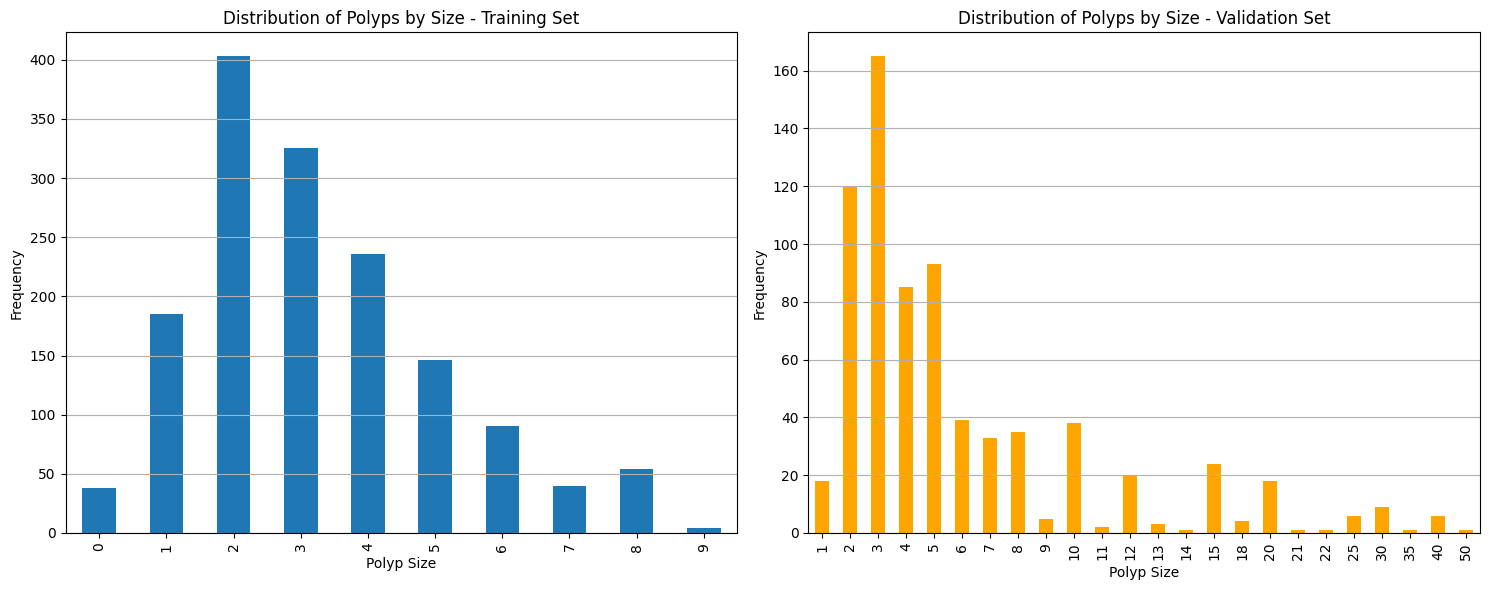

In [10]:
import matplotlib.pyplot as plt

# Remove entries with negative values from the size columns for both sets
train_set_filtered = train_set[train_set['SIZE'] >= 0]
validation_set_filtered = validation_set[validation_set['POLYP SIZE'] >= 0]

# Recalculate the distribution of polyps by size for the filtered data
size_distribution_train_filtered = train_set_filtered['SIZE'].value_counts().sort_index()
size_distribution_validation_filtered = validation_set_filtered['POLYP SIZE'].value_counts().sort_index()

# Plot histograms for the distribution of polyps by size for both sets
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
size_distribution_train_filtered.plot(kind='bar')
plt.title('Distribution of Polyps by Size - Training Set')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')

plt.subplot(1, 2, 2)
size_distribution_validation_filtered.plot(kind='bar', color='orange')
plt.title('Distribution of Polyps by Size - Validation Set')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# Distribution of polyp sizes. Descriptive statistics (excluding negative values)

In [11]:
# Extracting only the descriptive statistics for the polyp size in both sets
desc_stats_size_train = train_set_filtered['SIZE'].describe()
desc_stats_size_validation = validation_set_filtered['POLYP SIZE'].describe()

desc_stats_size_train, desc_stats_size_validation

(count    1521.000000
 mean        3.239974
 std         1.842733
 min         0.000000
 25%         2.000000
 50%         3.000000
 75%         4.000000
 max         9.000000
 Name: SIZE, dtype: float64,
 count    728.000000
 mean       6.350275
 std        6.380602
 min        1.000000
 25%        3.000000
 50%        4.000000
 75%        7.000000
 max       50.000000
 Name: POLYP SIZE, dtype: float64)

In [ ]:
# Distribution of polyp sizes. Box plot

<Figure size 800x600 with 0 Axes>

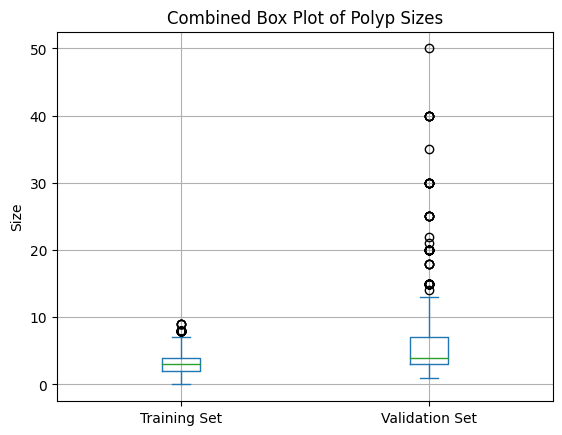

In [13]:
# Combine both training and validation sets into one DataFrame for a combined box plot
combined_sizes = pd.DataFrame({
    'Training Set': train_set_filtered['SIZE'],
    'Validation Set': validation_set_filtered['POLYP SIZE']
})

# Generate a combined vertical box plot for both sets
plt.figure(figsize=(8, 6))
combined_sizes.plot(kind='box')
plt.title('Combined Box Plot of Polyp Sizes')
plt.ylabel('Size')
plt.grid(True)
plt.show()

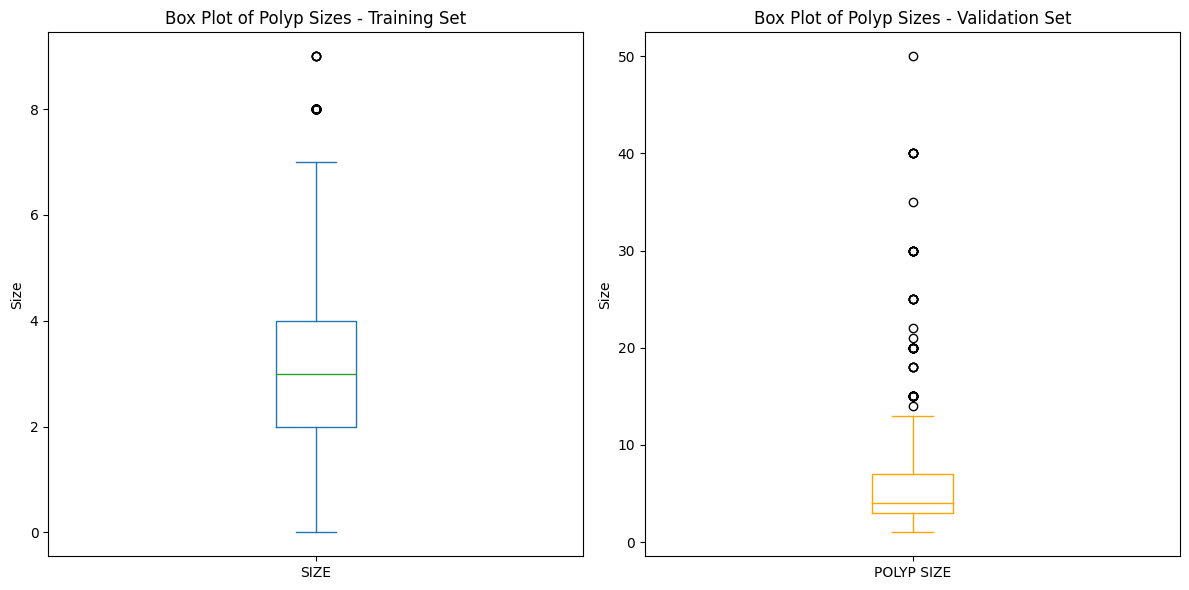

In [14]:
# Generate vertical box plots for the polyp sizes in the training and validation sets
plt.figure(figsize=(12, 6))

# Vertical box plot for the training set
plt.subplot(1, 2, 1)
train_set_filtered['SIZE'].plot(kind='box')
plt.title('Box Plot of Polyp Sizes - Training Set')
plt.ylabel('Size')

# Vertical box plot for the validation set
plt.subplot(1, 2, 2)
validation_set_filtered['POLYP SIZE'].plot(kind='box', color='orange')
plt.title('Box Plot of Polyp Sizes - Validation Set')
plt.ylabel('Size')

plt.tight_layout()
plt.show()

In [ ]:
# Distribution of polyp sizes. Train and validation sets together

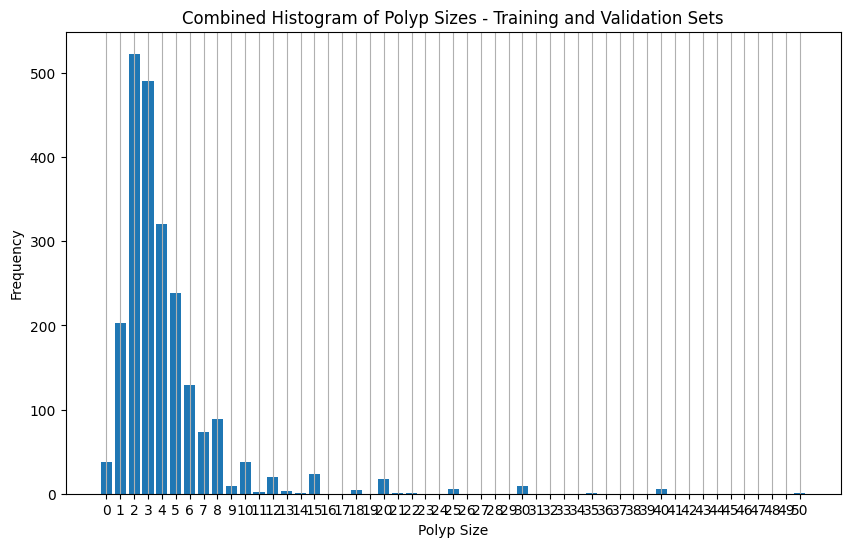

In [15]:
# Combine the polyp size data from both sets for a combined distribution analysis
combined_sizes_distribution = pd.concat([train_set_filtered['SIZE'], validation_set_filtered['POLYP SIZE']], ignore_index=True)

# Plot the histogram for the combined polyp size distribution
plt.figure(figsize=(10, 6))
combined_sizes_distribution.hist(bins=range(int(combined_sizes_distribution.max()) + 2), rwidth=0.8, align='left')
plt.title('Combined Histogram of Polyp Sizes - Training and Validation Sets')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')
plt.xticks(range(int(combined_sizes_distribution.max()) + 1))
plt.show()

In [ ]:
# Distribution of polyp sizes based on the different ranges considered by the authors: Diminutive Polyps (1-5 mm), Small Polyps (6-9 mm), Larger Polyps (>=10 mm)

SIZE
Diminutive (1-5 mm)    1295
Small (6-9 mm)          188
Larger (>=10 mm)          0
Name: count, dtype: int64 POLYP SIZE
Diminutive (1-5 mm)    481
Small (6-9 mm)         112
Larger (>=10 mm)       135
Name: count, dtype: int64


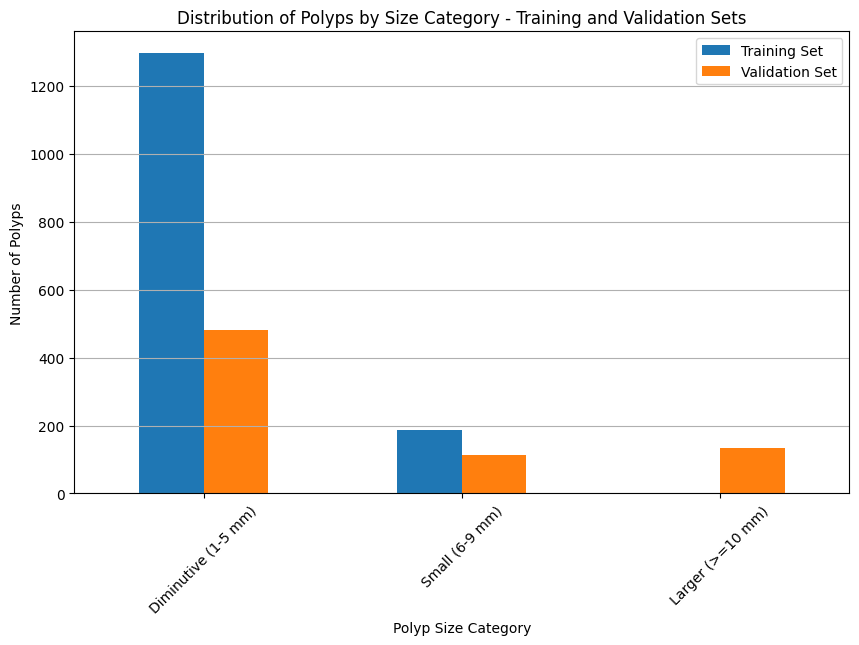

In [18]:
# Categorize polyp sizes into three groups for the training set
size_categories_train = pd.cut(train_set_filtered['SIZE'], bins=[0, 5, 9, float('inf')], labels=['Diminutive (1-5 mm)', 'Small (6-9 mm)', 'Larger (>=10 mm)'])

# Calculate the distribution of polyps by these size categories in the training set
size_category_distribution_train = size_categories_train.value_counts().sort_index()

# Categorize polyp sizes into three groups for the validation set
size_categories_validation = pd.cut(validation_set_filtered['POLYP SIZE'], bins=[0, 5, 9, float('inf')], labels=['Diminutive (1-5 mm)', 'Small (6-9 mm)', 'Larger (>=10 mm)'])

# Calculate the distribution of polyps by these size categories in the validation set
size_category_distribution_validation = size_categories_validation.value_counts().sort_index()

print(size_category_distribution_train, size_category_distribution_validation)

# Prepare data for bar chart
size_category_distribution_combined = pd.DataFrame({
    'Training Set': size_category_distribution_train,
    'Validation Set': size_category_distribution_validation
})

# Generate a bar chart for the distribution of polyp sizes in the training and validation sets
size_category_distribution_combined.plot(kind='bar', figsize=(10, 6))
plt.title('Distribution of Polyps by Size Category - Training and Validation Sets')
plt.xlabel('Polyp Size Category')
plt.ylabel('Number of Polyps')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


In [ ]:
# Distribution of polyp sizes based on the different ranges considered by the authors: Diminutive Polyps (1-5 mm), Small Polyps (6-9 mm), Larger Polyps (>=10 mm). Train and validation sets together

Diminutive (1-5 mm)    1776
Small (6-9 mm)          300
Larger (>=10 mm)        135
Name: count, dtype: int64


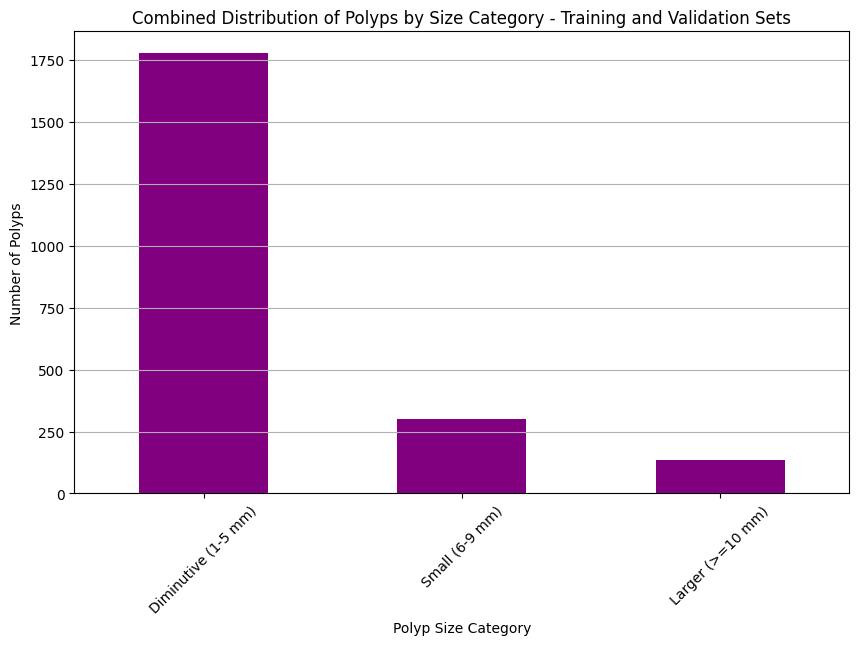

In [19]:
# Combine the size category distributions from both the training and validation sets
size_category_distribution_combined_all = pd.concat([size_categories_train, size_categories_validation]).value_counts().sort_index()

print(size_category_distribution_combined_all)

# Generate a bar chart for the combined distribution of polyp sizes
size_category_distribution_combined_all.plot(kind='bar', figsize=(10, 6), color='purple')
plt.title('Combined Distribution of Polyps by Size Category - Training and Validation Sets')
plt.xlabel('Polyp Size Category')
plt.ylabel('Number of Polyps')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [ ]:
# Distribution by pathology diagnosis

In [ ]:
# Calculate the distribution of polyps by pathology diagnosis for both sets
pathology_distribution_train = train_set_filtered['PATHOLOGY DIAGNOSIS'].value_counts()
pathology_distribution_validation = validation_set_filtered['PATHOLOGY DIAGNOSIS'].value_counts()

# Generate histograms for the distribution of polyps by pathology diagnosis
plt.figure(figsize=(15, 6))

# Histogram for the training set
plt.subplot(1, 2, 1)
pathology_distribution_train.plot(kind='bar')
plt.title('Pathology Diagnosis Distribution - Training Set')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)

# Histogram for the validation set
plt.subplot(1, 2, 2)
pathology_distribution_validation.plot(kind='bar', color='orange')
plt.title('Pathology Diagnosis Distribution - Validation Set')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

pathology_distribution_train, pathology_distribution_validation

In [ ]:
# Distribution by pathology diagnosis. Train and validation sets together

In [ ]:
# Remove the entry with '##USER_MISSING_99##' from the validation set for combined analysis
validation_set_filtered_cleaned = validation_set_filtered[validation_set_filtered['PATHOLOGY DIAGNOSIS'] != '##USER_MISSING_99##']

# Combine the pathology diagnosis data from both sets
combined_pathology = pd.concat([train_set_filtered['PATHOLOGY DIAGNOSIS'], validation_set_filtered_cleaned['PATHOLOGY DIAGNOSIS']])

# Calculate the combined distribution of polyps by pathology diagnosis
combined_pathology_distribution = combined_pathology.value_counts()

# Generate a histogram for the combined distribution
plt.figure(figsize=(12, 6))
combined_pathology_distribution.plot(kind='bar', color='green')
plt.title('Combined Pathology Diagnosis Distribution - Training and Validation Sets')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

combined_pathology_distribution